In [1]:
import pandas as pd
import numpy as np

df = pd.read_csv("zomato_cleaned.csv")

print(df.shape)
df.head()

(9551, 26)


,restaurant_id,restaurant_name,country_code,city,address,locality,locality_verbose,longitude,latitude,cuisines,...,aggregate_rating,rating_color,rating_text,votes,rating_status,rating_clean,log_votes,price_category,rating_category,primary_cuisine
0,6317637,Le Petit Souffle,162,Makati City,"Third Floor, Century City Mall, Kalayaan Avenu...","Century City Mall, Poblacion, Makati City","Century City Mall, Poblacion, Makati City, Mak...",121.027535,14.565443,"French, Japanese, Desserts",...,4.8,Dark Green,Excellent,314,Rated,4.8,5.752573,Premium,Excellent,French
1,6304287,Izakaya Kikufuji,162,Makati City,"Little Tokyo, 2277 Chino Roces Avenue, Legaspi...","Little Tokyo, Legaspi Village, Makati City","Little Tokyo, Legaspi Village, Makati City, Ma...",121.014101,14.553708,Japanese,...,4.5,Dark Green,Excellent,591,Rated,4.5,6.383507,Premium,Excellent,Japanese
2,6300002,Heat - Edsa Shangri-La,162,Mandaluyong City,"Edsa Shangri-La, 1 Garden Way, Ortigas, Mandal...","Edsa Shangri-La, Ortigas, Mandaluyong City","Edsa Shangri-La, Ortigas, Mandaluyong City, Ma...",121.056831,14.581404,"Seafood, Asian, Filipino, Indian",...,4.4,Green,Very Good,270,Rated,4.4,5.602119,Luxury,Very Good,Seafood
3,6318506,Ooma,162,Mandaluyong City,"Third Floor, Mega Fashion Hall, SM Megamall, O...","SM Megamall, Ortigas, Mandaluyong City","SM Megamall, Ortigas, Mandaluyong City, Mandal...",121.056475,14.585318,"Japanese, Sushi",...,4.9,Dark Green,Excellent,365,Rated,4.9,5.902633,Luxury,Excellent,Japanese
4,6314302,Sambo Kojin,162,Mandaluyong City,"Third Floor, Mega Atrium, SM Megamall, Ortigas...","SM Megamall, Ortigas, Mandaluyong City","SM Megamall, Ortigas, Mandaluyong City, Mandal...",121.057508,14.584450,"Japanese, Korean",...,4.8,Dark Green,Excellent,229,Rated,4.8,5.438079,Luxury,Excellent,Japanese


In [2]:
features = [
    "price_range",
    "rating_clean",
    "log_votes",
    "has_online_delivery",
    "has_table_booking",
    "is_delivering_now",
    "latitude",
    "longitude"
]

X = df[features].copy()

In [3]:
X["rating_clean"] = X["rating_clean"].fillna(
    X["rating_clean"].median()
)

In [4]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

[60490.84848237945]
[60490.84848237945, 50816.236071893705]
[60490.84848237945, 50816.236071893705, 42021.6559372388]
[60490.84848237945, 50816.236071893705, 42021.6559372388, 33564.840206833986]
[60490.84848237945, 50816.236071893705, 42021.6559372388, 33564.840206833986, 27091.253373778687]
[60490.84848237945, 50816.236071893705, 42021.6559372388, 33564.840206833986, 27091.253373778687, 21934.670147259356]
[60490.84848237945, 50816.236071893705, 42021.6559372388, 33564.840206833986, 27091.253373778687, 21934.670147259356, 19668.195058124707]
[60490.84848237945, 50816.236071893705, 42021.6559372388, 33564.840206833986, 27091.253373778687, 21934.670147259356, 19668.195058124707, 17663.600048554697]
[60490.84848237945, 50816.236071893705, 42021.6559372388, 33564.840206833986, 27091.253373778687, 21934.670147259356, 19668.195058124707, 17663.600048554697, 16047.263963870137]


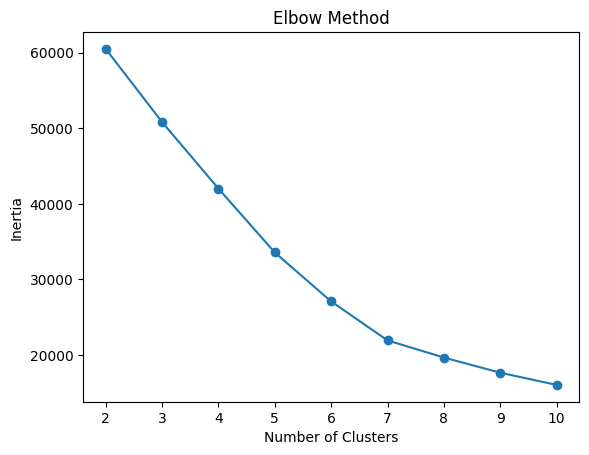

In [13]:
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

inertia = []

for k in range(2, 11):
    kmeans = KMeans(n_clusters=k,random_state=42,n_init=10)
    
    kmeans.fit(X_scaled)
    inertia.append(kmeans.inertia_)
    print(inertia)

plt.plot(range(2, 11), inertia, marker="o")
plt.xlabel("Number of Clusters")
plt.ylabel("Inertia")
plt.title("Elbow Method")
plt.show()

In [16]:
# K-Means with 6 clusters
kmeans = KMeans(
    n_clusters=4,
    random_state=42,
    n_init=10
)


df["cluster"] = kmeans.fit_predict(X_scaled)
print(df["cluster"].value_counts().sort_index())

cluster
0    5980
1    2380
2    1157
3      34
Name: count, dtype: int64


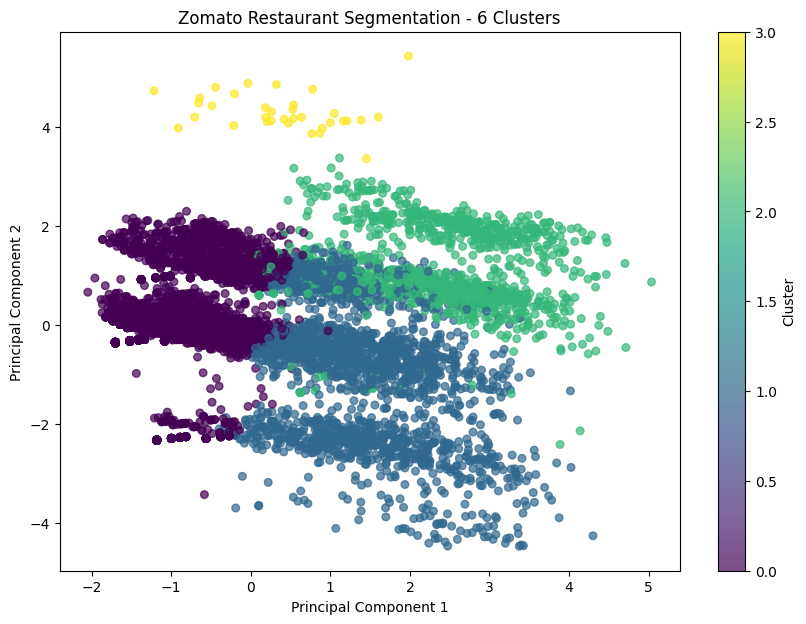

In [17]:
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

# Reduce 8 features to 2 dimensions
pca = PCA(n_components=2)

X_pca = pca.fit_transform(X_scaled)

# Plot
plt.figure(figsize=(10, 7))

scatter = plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=df["cluster"],
    cmap="viridis",
    s=30,
    alpha=0.7
)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("Zomato Restaurant Segmentation - 6 Clusters")

plt.colorbar(
    scatter,
    label="Cluster"
)

plt.show()

In [7]:
cluster_summary = df.groupby("cluster").agg(
    restaurants=("restaurant_id", "count"),
    avg_price=("price_range", "mean"),
    avg_rating=("rating_clean", "mean"),
    avg_votes=("votes", "mean"),
    delivery_rate=("has_online_delivery", "mean"),
    booking_rate=("has_table_booking", "mean")
)

print(cluster_summary)

         restaurants  avg_price  avg_rating   avg_votes  delivery_rate  \
cluster                                                                  
0               5980   1.330268    3.088935   26.233445       0.216890   
1               2380   2.400000    3.948147  389.866387       0.288235   
2               1157   3.028522    3.588108  353.350908       0.375108   
3                 34   1.970588    3.248485  148.823529       1.000000   

         booking_rate  
cluster                
0            0.000000  
1            0.000000  
2            1.000000  
3            0.029412  


In [8]:
df.to_csv("zomato_segmented.csv", index=False)

In [9]:
budget_map = {
    "Budget": 1,
    "Mid-Range": 2,
    "Premium": 3,
    "Luxury": 4
}

In [10]:
def recommend_restaurants(
    budget="Budget",
    city=None,
    cuisine=None,
    min_rating=0,
    online_delivery=None,
    top_n=10
):
    
    price_value = budget_map[budget]

    result = df[df["price_range"] == price_value].copy()

    if city:
        result = result[
            result["city"].str.lower() == city.lower()
        ]

    if cuisine:
        result = result[
            result["cuisines"]
            .fillna("")
            .str.lower()
            .str.contains(cuisine.lower(), na=False)
        ]

    if min_rating > 0:
        result = result[
            result["rating_clean"] >= min_rating
        ]

    if online_delivery is not None:
        result = result[
            result["has_online_delivery"] == online_delivery
        ]

    # Recommendation score
    result["recommendation_score"] = (
        result["rating_clean"] * 0.6
        + np.log1p(result["votes"]) * 0.4
    )

    result = result.sort_values(
        "recommendation_score",
        ascending=False
    )

    return result.head(top_n)

In [11]:
recommendations = recommend_restaurants(
    budget="Budget"
)

print(
    recommendations[
        [
            "restaurant_name",
            "city",
            "cuisines",
            "price_range",
            "rating_clean",
            "votes"
        ]
    ]
)

                             restaurant_name                    city  \
3013                      Naturals Ice Cream               New Delhi   
3119                                Wenger's               New Delhi   
507                 Mazzaro's Italian Market               Tampa Bay   
2418               Grandson of Tunday Kababi                 Lucknow   
3599                           Andhra Bhavan               New Delhi   
513                                 Taco Bus               Tampa Bay   
811                          Fusilli Reasons                 Chennai   
175                  Shorts Burger and Shine  Cedar Rapids/Iowa City   
391   Original Georgios Authentic Greek Food               Pensacola   
429                            Marukame Udon          Rest of Hawaii   

                         cuisines  price_range  rating_clean  votes  
3013                    Ice Cream            1           4.9   2620  
3119  Bakery, Fast Food, Desserts            1           4.3   3591

In [12]:
recommendations = recommend_restaurants(
    budget="Budget",
    city="Bangalore"
)

print(recommendations)

     restaurant_id restaurant_name  country_code       city  \
737       18305628      Eat Street             1  Bangalore   

                                               address               locality  \
737  11, 80 Feet Road, Opposite Indian Oil Petrol P...  Koramangala 6th Block   

                     locality_verbose  longitude   latitude  \
737  Koramangala 6th Block, Bangalore  77.625999  12.939496   

                                              cuisines  ...  rating_text  \
737  North Indian, Chinese, Italian, Street Food, D...  ...    Very Good   

    votes  rating_status  rating_clean  log_votes  price_category  \
737   753          Rated           4.3   6.625392          Budget   

     rating_category primary_cuisine cluster  recommendation_score  
737        Very Good    North Indian       1              5.230157  

[1 rows x 28 columns]
